In [69]:
from pathlib import Path
import os

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from src.pipeline import DataAnalyzer

In [70]:
import importlib
from src import pipeline

importlib.reload(pipeline)

analyzer = pipeline.DataAnalyzer("data/processed/online_retail.csv")

df = analyzer.load_csv()

print(df.shape)
display(df.head())

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [71]:
df.info()
display(df.describe())
display(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(2), string(3)
memory usage: 33.1 MB


,Quantity,InvoiceDate,UnitPrice
count,541909.000000,541909,541909.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114
min,-80995.000000,2010-12-01 08:26:00,-11062.060000
25%,1.000000,2011-03-28 11:34:00,1.250000
50%,3.000000,2011-07-19 17:17:00,2.080000
75%,10.000000,2011-10-19 11:27:00,4.130000
max,80995.000000,2011-12-09 12:50:00,38970.000000
std,218.081158,NaN,96.759853


InvoiceNo              string
StockCode              string
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID             string
Country                   str
dtype: object

In [72]:
missing_before = analyzer.missing_summary()
display(missing_before)

df            = analyzer.handle_missing_values()
missing_after = analyzer.missing_summary()
display(missing_after)

,count,percent
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


,count,percent
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


In [73]:
sales    = analyzer.get_sales_data()
outliers = analyzer.detect_outliers("Quantity", sales)

print("전체 판매 데이터:", len(sales))
print("Quantity 이상치:", len(outliers))

display(outliers.head())

전체 판매 데이터: 530104
Quantity 이상치: 56363


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom,54.08
26,536370,22728,ALARM CLOCK BAKELIKE PINK,24,2010-12-01 08:45:00,3.75,12583.0,France,90.00
27,536370,22727,ALARM CLOCK BAKELIKE RED,24,2010-12-01 08:45:00,3.75,12583.0,France,90.00
30,536370,21883,STARS GIFT TAPE,24,2010-12-01 08:45:00,0.65,12583.0,France,15.60
31,536370,10002,INFLATABLE POLITICAL GLOBE,48,2010-12-01 08:45:00,0.85,12583.0,France,40.80


In [74]:
import matplotlib.pyplot as plt
import seaborn           as sns

from pathlib import Path

Path("figures").mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

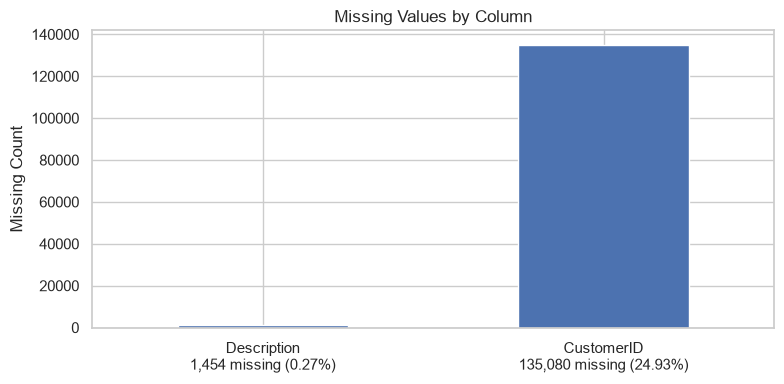

In [75]:
missing = missing_before["count"]
missing = missing[missing > 0]

plt.figure(figsize=(8, 4))
missing.plot(kind="bar")

plt.title("Missing Values by Column")
plt.ylabel("Missing Count")
labels = [
    f"{column}\n{count:,} missing ({missing_before.loc[column, 'percent']:.2f}%)"
    for column, count in missing.items()
]
plt.xticks(range(len(missing)), labels, rotation=0, ha="center")

plt.tight_layout()
plt.savefig("figures/01_missing.png")
plt.show()

## 차트 1. 열별 결측값 개수

### 값 소개

- Missing Values by Column => 열별 결측값 개수 (제목)
- Missing Count            => 값이 비어 있는 행의 개수 (세로축)
- Description => 상품 설명
- CustomerID  => 고객 ID

### 결측값이란?

=> 데이터에서 값이 입력되지 않았거나 누락되어 비어 있는 값.

### 해당 차트로 알 수 있는 건?

=> 전체 541,909행 중 상품 설명은 1,454행(약 0.27%), 고객 ID는 135,080행(약 24.93%)이 비어 있음. 고객 ID는 약 4행 중 1행이 누락되어 있어, 고객별 구매 분석 시 처리 기준이 필요함. 여기서 개수는 고객 수가 아닌 행 수를 뜻함.

### 막대 높이가 크게 다른 이유는?

=> 결측값이 0개인 열은 제외해서 막대가 두 개만 나옴. 고객 ID의 결측값이 상품 설명보다 약 93배 많아, 같은 세로축에서 상품 설명 막대가 거의 바닥에 붙어 보이는 것.

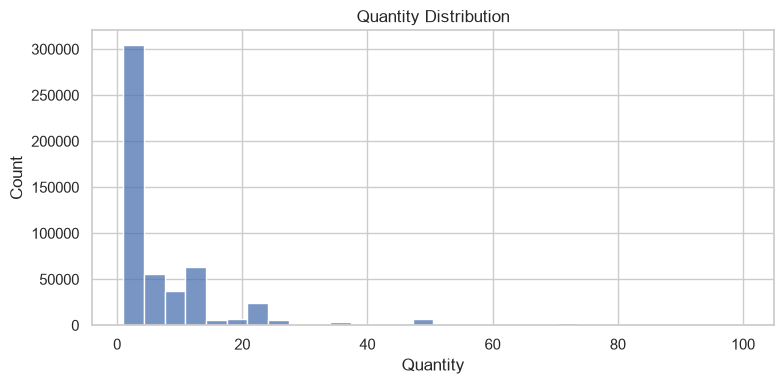

In [76]:
limit = sales["Quantity"].quantile(0.99)
data  = sales.loc[sales["Quantity"] <= limit, "Quantity"]

plt.figure(figsize=(8, 4))
sns.histplot(data, bins=30)

plt.title("Quantity Distribution")
plt.xlabel("Quantity")

plt.tight_layout()
plt.savefig("figures/02_quantity.png")
plt.show()

## 차트 2. 판매 수량 분포

### 값 소개

- Quantity Distribution => 판매 수량 분포 (제목)
- Quantity => 각 행의 판매 수량 (가로축)
- Count => 해당 수량 구간에 속하는 행의 개수 (세로축)

### 해당 차트로 알 수 있는 건?

=> 수량을 구간별로 묶어 빈도를 나타낸 히스토그램. 판매 데이터의 수량 중앙값은 3개이며, 75%는 10개 이하라 작은 수량 쪽에 행이 몰려 있음. 여기서 한 행은 주문 전체가 아닌 상품별 거래 기록을 뜻함.

### 일부 수량이 안 보이는 이유는?

=> 큰 값 때문에 분포가 눌리지 않도록 99백분위수인 100개 이하만 표시함. 100개를 초과하는 4,849행은 이 그림에서만 제외되며, 원본 판매 데이터에서는 삭제되지 않음. 이후 차트는 수량·단가가 양수이고 취소 번호가 아닌 판매 데이터를 기준으로 함.

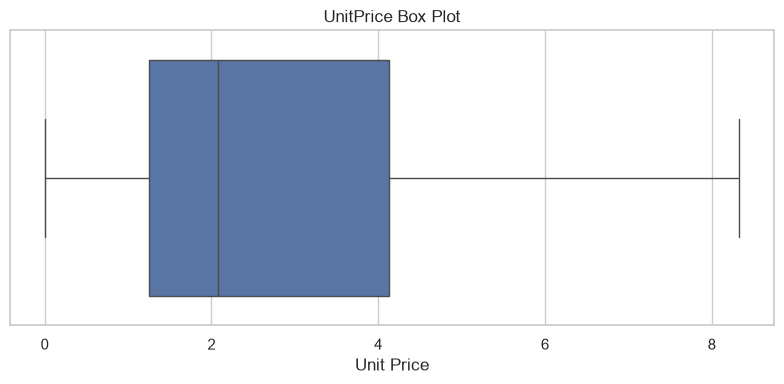

In [77]:
plt.figure(figsize=(8,4))
sns.boxplot(x=sales["UnitPrice"], showfliers=False)

plt.title("UnitPrice Box Plot")
plt.xlabel("Unit Price")

plt.tight_layout()
plt.savefig("figures/03_price_box.png")
plt.show()

## 차트 3. 상품 단가 분포

### 값 소개

- UnitPrice Box Plot => 상품 단가 상자그림 (제목)
- Unit Price => 상품 1개당 가격 (가로축)

### 상자그림이란?

=> 상자는 단가의 하위 25%부터 75%까지, 상자 안의 선은 중앙값을 나타냄. 수염은 보통 상자 길이(IQR)의 1.5배 범위 안에 있는 실제 값까지 표시함.

### 해당 차트로 알 수 있는 건?

=> 단가의 가운데 50%는 1.25~4.13에 있고 중앙값은 2.08임. 상자가 보여주는 것은 주로 거래되는 단가 범위이며, 전체 최솟값·최댓값 범위는 아님.

### 이상치가 안 보이는 이유는?

=> `showfliers=False`로 수염 밖의 이상치 점을 숨겼기 때문. 이상치를 데이터에서 제거한 것은 아니며, 이상치라는 이유만으로 잘못 입력된 값이라고 단정할 수 없음.

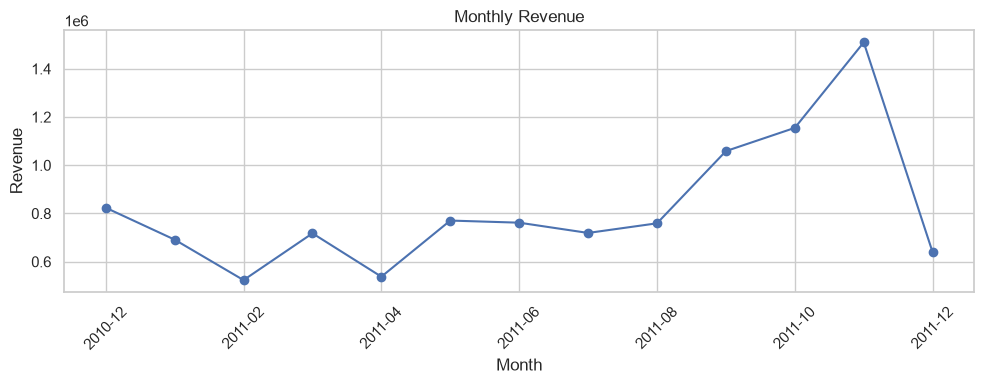

In [78]:
monthly = sales.groupby(sales["InvoiceDate"].dt.to_period("M"))["Revenue"].sum()
monthly.index = monthly.index.astype(str)

plt.figure(figsize=(10, 4))
monthly.plot(marker="o")

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("figures/04_monthly.png")
plt.show()

## 차트 4. 월별 매출 추이

### 값 소개

- Monthly Revenue => 월별 매출 (제목)
- Month => 거래 월 (가로축)
- Revenue => 수량 × 단가를 월별로 합산한 금액 (세로축)

### 해당 차트로 알 수 있는 건?

=> 2011년 9~11월 매출이 연속으로 증가하며, 11월이 약 151만으로 가장 높음. 취소·음수 수량 등을 제외한 판매 금액이므로 반품을 차감한 순매출과는 구분해야 함.

### 마지막 달 매출이 줄어든 이유는?

=> 데이터가 2011년 12월 9일까지만 있어 마지막 달은 한 달 전체가 아님. 11월보다 낮다는 이유만으로 실제 월 매출이 감소했다고 판단할 수 없음.

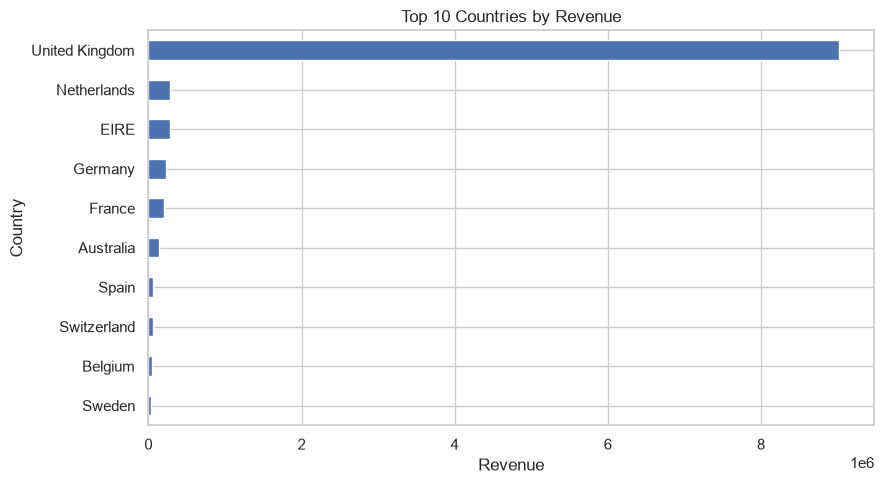

In [79]:
countries = (
    sales.groupby("Country")["Revenue"]
    .sum().nlargest(10).sort_values()
)

plt.figure(figsize=(9, 5))
countries.plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")

plt.tight_layout()
plt.savefig("figures/05_countries.png")
plt.show()

## 차트 5. 국가별 매출 상위 10개

### 값 소개

- Top 10 Countries by Revenue => 매출 상위 10개 국가 (제목)
- Revenue => 국가별 판매 금액 합계 (가로축)
- Country => 국가명 (세로축)

### 해당 차트로 알 수 있는 건?

=> 영국 매출이 약 903만으로, 전체 국가 매출의 약 84.61%를 차지함. 이 데이터의 판매가 영국에 크게 집중되어 있고, 네덜란드·아일랜드·독일 등이 뒤를 이음. 국가별 고객 수나 시장 전체 규모를 의미하는 것은 아님.

### 막대가 이런 순서로 나온 이유는?

=> 매출 상위 10개 국가를 뽑은 뒤 오름차순으로 정렬해 가로 막대로 표시함. 가장 큰 값인 영국이 맨 위에 배치됨.

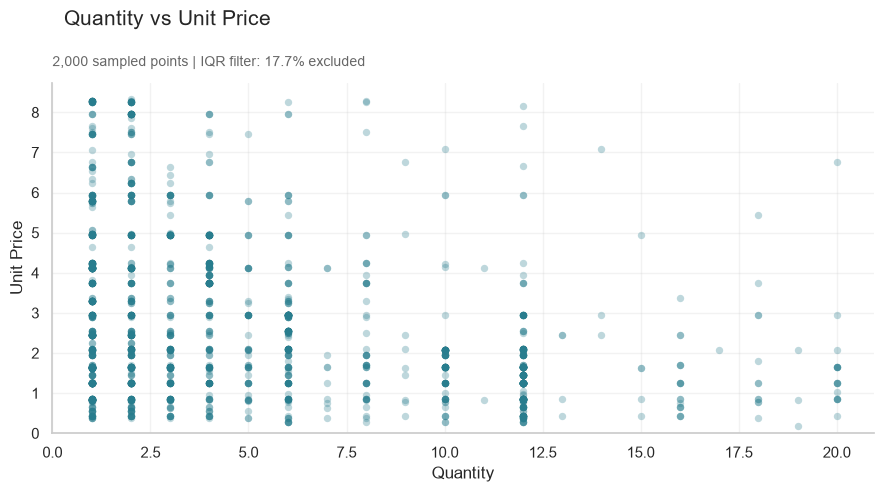

전체 판매 데이터: 530,104행
차트용 데이터: 436,166행
IQR 기준 제외: 93,938행 (17.72%)


In [80]:
def plot_quantity_price(sales, analyzer):
    import matplotlib.pyplot as plt
    import seaborn as sns

    with sns.axes_style("whitegrid"):
        quantity_outliers = analyzer.detect_outliers("Quantity", sales)
        price_outliers = analyzer.detect_outliers("UnitPrice", sales)
        excluded_indices = quantity_outliers.index.union(price_outliers.index)

        scatter_data = sales.drop(index=excluded_indices)
        sample = scatter_data.sample(
            n=min(2000, len(scatter_data)),
            random_state=42
        )
        excluded_percent = len(excluded_indices) / len(sales) * 100

        fig, ax = plt.subplots(figsize=(9, 5))
        sns.scatterplot(
            data=sample,
            x="Quantity",
            y="UnitPrice",
            s=28,
            alpha=0.3,
            color="#287D8E",
            linewidth=0,
            ax=ax
        )

        fig.suptitle(
            "Quantity vs Unit Price",
            x=0.08, ha="left", fontsize=15
        )
        ax.set_title(
            f"{len(sample):,} sampled points | IQR filter: {excluded_percent:.1f}% excluded",
            loc="left", fontsize=10, color="#666666", pad=12
        )
        ax.set_xlabel("Quantity")
        ax.set_ylabel("Unit Price")
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.25)
        ax.set_axisbelow(True)
        sns.despine(ax=ax)

        fig.tight_layout()
        fig.savefig("figures/06_scatter.png", dpi=150)
        plt.show()

        print(f"전체 판매 데이터: {len(sales):,}행")
        print(f"차트용 데이터: {len(scatter_data):,}행")
        print(f"IQR 기준 제외: {len(excluded_indices):,}행 ({excluded_percent:.2f}%)")

plot_quantity_price(sales, analyzer)

## 차트 6. 극단값을 제외한 판매 수량과 단가의 관계

### 값 소개

- Quantity vs Unit Price => 판매 수량과 단가의 관계 (제목)
- Quantity => 판매 수량 (가로축)
- Unit Price => 상품 1개당 가격 (세로축)

### 어떤 값을 제외했나?

=> 전체 판매 데이터에서 수량과 단가 각각의 IQR 기준을 계산하고, 둘 중 하나라도 기준 밖이면 차트에서 제외함. 기준은 하위 25% 값 − 1.5 × IQR부터 상위 25% 경계값(Q3) + 1.5 × IQR까지이며, IQR은 Q3 − Q1임.

=> 현재 판매 데이터에서는 수량 23.5 초과 또는 단가 8.45 초과인 행이 제외됨. 전체 530,104행 중 93,938행(약 17.72%)을 제외한 436,166행을 차트용으로 사용함. 원본 판매 데이터와 다른 차트의 계산에는 영향을 주지 않음.

### 점 하나는 무엇을 뜻하나?

=> 남은 데이터에서 무작위로 뽑은 2,000행 중 하나를 뜻함. random_state=42로 고정해 같은 표본을 사용하고, 점을 반투명하게 표시해 겹치는 곳이 더 진하게 보이도록 함.

### 해당 차트로 알 수 있는 건?

=> 극단값이 축을 크게 늘리던 문제가 줄어 일반적인 수량·단가 구간을 살펴보기 쉬워짐. 수량이 정수여서 같은 수량의 점들이 세로로 줄지어 보일 수 있음. 필터링한 표본의 분포이므로 전체 거래를 대표하거나 수량과 가격의 인과관계를 보여주는 것은 아님.

In [81]:
from pathlib import Path

import pandas as pd


def main() -> None:
    project_root = Path(__file__).resolve().parents[2]
    csv_path = project_root / "data/processed/online_retail.csv"
    parquet_path = csv_path.with_suffix(".parquet")

    df = pd.read_csv(
        csv_path,
        dtype={
            "InvoiceNo": "string",
            "StockCode": "string",
            "CustomerID": "string",
        },
        parse_dates=["InvoiceDate"],
    )

    df.to_parquet(parquet_path, engine="pyarrow", compression="snappy", index=False)

    print(f"Saved: {parquet_path}")
    print(f"Rows: {len(df):,}, Columns: {len(df.columns)}")


In [84]:
import pandas as pd
import numpy  as np

image_df = pd.read_csv("data/processed/fashion-mnist_test.csv", nrows=1000)

print(image_df.shape)
display(image_df.head())

(1000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [85]:
images = image_df.iloc[:, 1:].to_numpy(dtype=np.uint8)
print(images.shape)

images = images.reshape(-1, 28, 28)
print(images.shape)

(1000, 784)
(1000, 28, 28)


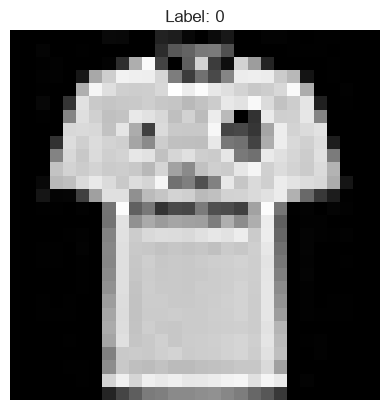

In [86]:
import matplotlib.pyplot as plt

plt.imshow(images[0], cmap="gray", vmin=0, vmax=255)
plt.title(f"Label: {image_df['label'].iloc[0]}")
plt.axis("off")
plt.show()